# Dataset statistics

Exploratory analysis of the drone-detection dataset (3 classes: AirPlane, Drone,
Helicopter) used to support the results discussion:
1. class distribution per split (imbalance),
2. fraction of background-only images,
3. object size distribution (small-object difficulty),
4. objects per image (relevant to the one-object-per-cell YOLOv1 head),
5. sample images with ground-truth boxes.

In [1]:
import sys
import os
from pathlib import Path
from collections import Counter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import matplotlib.pyplot as plt

from src.datasets.drone_detection_yolo import DroneDetectionYoloDataset
from src.utils.visualization import draw_boxes

CLASS_NAMES = ["AirPlane", "Drone", "Helicopter"]
SPLITS = ["train", "valid", "test"]
DATA_ROOT = Path("data")


def read_labels(label_path):
    """Return list of (cls, xc, yc, w, h) floats for one label file (empty if none)."""
    if not label_path.is_file():
        return []
    rows = []
    for line in label_path.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) >= 5:
            c, xc, yc, w, h = map(float, parts[:5])
            rows.append((int(c), xc, yc, w, h))
    return rows


# Collect all boxes per split once.
split_boxes = {}
split_empty = {}
split_objects_per_image = {}
for split in SPLITS:
    label_dir = DATA_ROOT / split / "labels"
    boxes, empties, per_image = [], 0, []
    for lp in sorted(label_dir.glob("*.txt")):
        rows = read_labels(lp)
        per_image.append(len(rows))
        if not rows:
            empties += 1
        boxes.extend(rows)
    split_boxes[split] = boxes
    split_empty[split] = (empties, len(per_image))
    split_objects_per_image[split] = per_image
    print(f"{split:6s}: {len(per_image)} images, {len(boxes)} objects, {empties} empty")

train : 10799 images, 8999 objects, 1979 empty
valid : 603 images, 497 objects, 110 empty
test  : 596 images, 479 objects, 123 empty


## 1. Class distribution

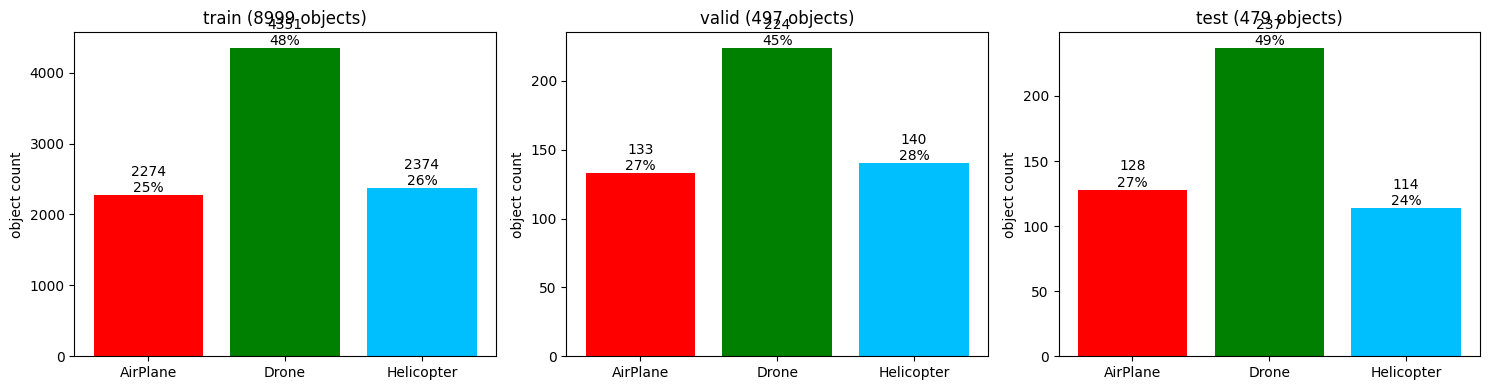

In [2]:
fig, axes = plt.subplots(1, len(SPLITS), figsize=(5 * len(SPLITS), 4), sharey=False)
for ax, split in zip(axes, SPLITS):
    counts = Counter(c for (c, *_) in split_boxes[split])
    values = [counts.get(i, 0) for i in range(len(CLASS_NAMES))]
    total = sum(values) or 1
    bars = ax.bar(CLASS_NAMES, values, color=["red", "green", "deepskyblue"])
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width()/2, v, f"{v}\n{100*v/total:.0f}%",
                ha="center", va="bottom")
    ax.set_title(f"{split} ({total} objects)")
    ax.set_ylabel("object count")
plt.tight_layout()
plt.show()

## 2. Background-only (empty) images

Images with no annotated object. They act as hard negatives during training (help
suppress false positives) but a large fraction can bias the objectness score.

In [3]:
for split in SPLITS:
    empties, total = split_empty[split]
    print(f"{split:6s}: {empties}/{total} empty ({100*empties/max(total,1):.1f}%)")

train : 1979/10799 empty (18.3%)
valid : 110/603 empty (18.2%)
test  : 123/596 empty (20.6%)


## 3. Object size distribution

Box area as a fraction of the image (`w * h`, normalized). Small objects are hard
for a coarse grid head; we also report the equivalent box side in pixels at 128px
(baseline) and 640px (ultralytics).

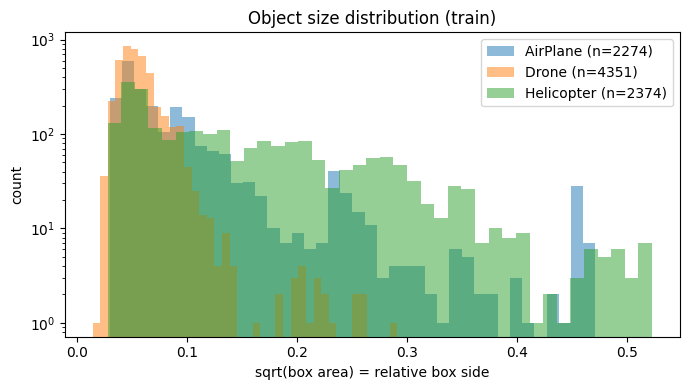

p10: side=0.039 of image  ->    5.0px @128  |    25.2px @640
p25: side=0.046 of image  ->    5.9px @128  |    29.5px @640
p50: side=0.058 of image  ->    7.4px @128  |    37.2px @640
p75: side=0.094 of image  ->   12.0px @128  |    59.9px @640
p90: side=0.188 of image  ->   24.0px @128  |   120.0px @640


In [4]:
areas_by_class = {i: [] for i in range(len(CLASS_NAMES))}
for (c, xc, yc, w, h) in split_boxes["train"]:
    areas_by_class[c].append(w * h)

fig, ax = plt.subplots(figsize=(7, 4))
for i, name in enumerate(CLASS_NAMES):
    a = np.array(areas_by_class[i])
    if len(a):
        ax.hist(np.sqrt(a), bins=40, alpha=0.5, label=f"{name} (n={len(a)})")
ax.set_xlabel("sqrt(box area) = relative box side")
ax.set_ylabel("count")
ax.set_yscale("log")
ax.set_title("Object size distribution (train)")
ax.legend()
plt.tight_layout()
plt.show()

all_sides = np.sqrt([w * h for (_, _, _, w, h) in split_boxes["train"]])
for pct in [10, 25, 50, 75, 90]:
    rel = np.percentile(all_sides, pct)
    print(f"p{pct:>2}: side={rel:.3f} of image  ->  {rel*128:5.1f}px @128  |  {rel*640:6.1f}px @640")

## 4. Objects per image

The YOLOv1 baseline head can predict at most one object per grid cell, so images
with many close objects are a known failure mode.

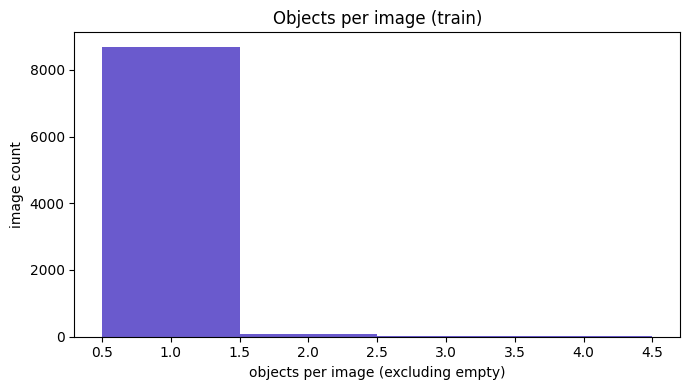

max objects in one image: 4
mean objects per non-empty image: 1.02


In [5]:
per_image = [n for n in split_objects_per_image["train"] if n > 0]
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(per_image, bins=range(1, max(per_image) + 2), align="left", color="slateblue")
ax.set_xlabel("objects per image (excluding empty)")
ax.set_ylabel("image count")
ax.set_title("Objects per image (train)")
plt.tight_layout()
plt.show()
print(f"max objects in one image: {max(per_image)}")
print(f"mean objects per non-empty image: {np.mean(per_image):.2f}")

## 5. Sample images with ground-truth boxes

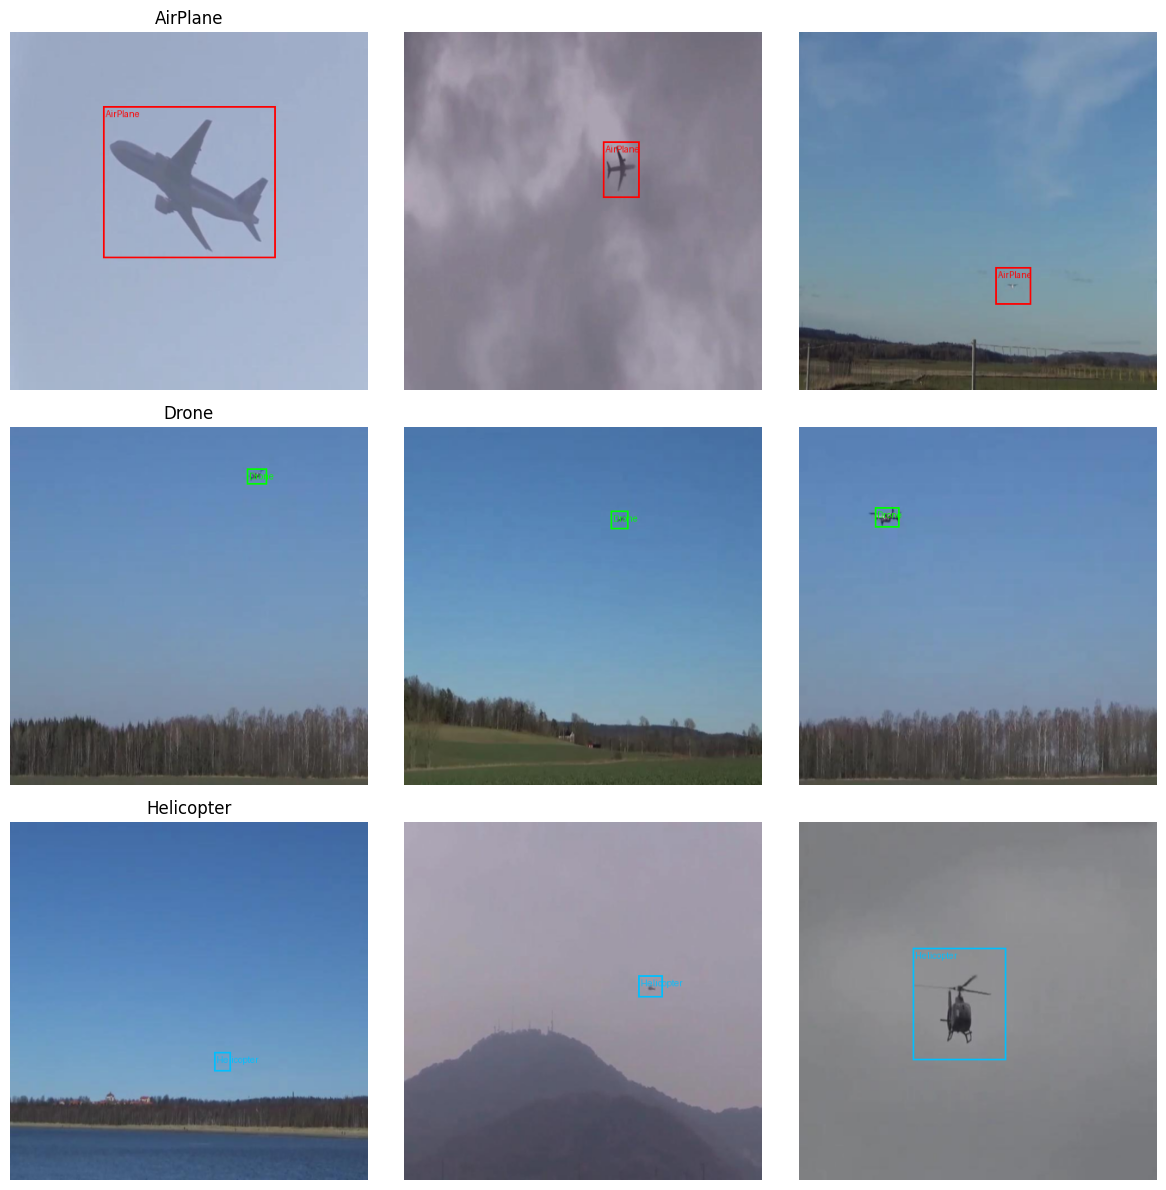

In [6]:
import torch

dataset = DroneDetectionYoloDataset(DATA_ROOT / "train", img_size=416)
rng = np.random.default_rng(0)

# Find a few images containing each class.
examples = {i: [] for i in range(len(CLASS_NAMES))}
for idx in rng.permutation(len(dataset)):
    sample = dataset[int(idx)]
    t = sample["targets"]
    if len(t) == 0:
        continue
    for c in set(int(x) for x in t[:, 0].tolist()):
        if len(examples[c]) < 3:
            examples[c].append(int(idx))
    if all(len(v) >= 3 for v in examples.values()):
        break

fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(12, 4 * len(CLASS_NAMES)))
for r, name in enumerate(CLASS_NAMES):
    for col, idx in enumerate(examples[r]):
        sample = dataset[idx]
        t = sample["targets"]
        size = dataset.img_size
        boxes = torch.stack([(t[:,1]-t[:,3]/2)*size, (t[:,2]-t[:,4]/2)*size,
                             (t[:,1]+t[:,3]/2)*size, (t[:,2]+t[:,4]/2)*size], dim=1)
        axes[r, col].imshow(draw_boxes(sample["image"], boxes, t[:, 0].long(), CLASS_NAMES))
        axes[r, col].set_title(name if col == 0 else "")
        axes[r, col].axis("off")
plt.tight_layout()
plt.show()